In [51]:
#Práctica 5 Rental Bikes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga del dataset
df = pd.read_csv("bike_rentals.csv")

# Exploración inicial
print("=== FORMA DEL DATASET ===")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")

print("\n=== PRIMERAS FILAS ===")
print(df.head())

print("\n=== TIPOS DE DATOS ===")
print(df.dtypes)

print("\n=== ESTADÍSTICAS BÁSICAS ===")
print(df.describe())

=== FORMA DEL DATASET ===
Filas: 731 | Columnas: 13

=== PRIMERAS FILAS ===
   instant  season      yr     mnth holiday    weekday workingday weathersit  \
0        1  spring  2011.0  January      no   Saturday         no     Cloudy   
1        2  spring  2011.0  January      no     Sunday         no     Cloudy   
2        3  spring  2011.0  January      no     Monday        yes      Clear   
3        4  spring  2011.0  January      no    Tuesday        yes      Clear   
4        5  spring  2011.0  January      no  Wednesday        yes      Clear   

       temp    atemp      hum  windspeed   cnt  
0  4.110847  3.18125  80.5833  10.749882   985  
1  4.902598  2.68695  69.6087  16.652113   801  
2 -1.949076 -5.52975  43.7273  16.636703  1349  
3 -1.800000 -4.39390  59.0435  10.739832  1562  
4 -0.694763 -3.53650  43.6957  12.522300  1600  

=== TIPOS DE DATOS ===
instant         int64
season         object
yr            float64
mnth           object
holiday        object
weekday        

#Problemas detectados:

instant — es solo un índice, hay que eliminarlo

yr — es float64 pero debería ser int (o categórica)

mnth, season, weekday, weathersit — son object (texto), hay que convertirlas

holiday, workingday — son object con valores yes/no, hay que convertirlas a 0/1

hum tiene un mínimo de 0.0 — sospechoso, podría ser un nulo disfrazado

In [52]:
# Normalizar nombres de columnas (venían bien)
df.columns = df.columns.str.strip().str.lower()

print("=== COLUMNAS NORMALIZADAS ===")
print(df.columns.tolist())

print("\n=== VALORES NULOS POR COLUMNA ===")
print(df.isnull().sum())

print("\n=== VALORES ÚNICOS EN COLUMNAS CATEGÓRICAS ===")
for col in ['season', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']:
    print(f"\n{col}: {df[col].unique()}")

=== COLUMNAS NORMALIZADAS ===
['instant', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']

=== VALORES NULOS POR COLUMNA ===
instant       0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
cnt           0
dtype: int64

=== VALORES ÚNICOS EN COLUMNAS CATEGÓRICAS ===

season: ['spring' 'summer' 'autumn' 'winter']

mnth: ['January' 'February' 'March' 'April' 'May' 'June' 'July' 'August'
 'September' 'October' 'November' 'December']

holiday: ['no' 'yes']

weekday: ['Saturday' 'Sunday' 'Monday' 'Tuesday' 'Wednesday' 'Thursday' 'Friday']

workingday: ['no' 'yes']

weathersit: ['Cloudy' 'Clear' 'Rain/snow']


# Renombrar columnas a nombres descriptivos

- yr -> year
- mnth -> month
- hum -> humidity
- temp -> feels_like_temp - sensación térmica
- weathersit weather - target
- windspeed wind_speed

In [53]:
# Renombrar columnas a nombres descriptivos
df = df.rename(columns={
    'yr'         : 'year',
    'mnth'       : 'month',
    'hum'        : 'humidity',
    'atemp'      : 'feels_like_temp',
    'weathersit' : 'weather',
    'cnt'        : 'rentals',
    'windspeed'  : 'wind_speed'
})

# Verificación
print("=== COLUMNAS RENOMBRADAS ===")
print(df.columns.tolist())

print("\n=== PRIMERAS FILAS ===")
print(df.head())

=== COLUMNAS RENOMBRADAS ===
['instant', 'season', 'year', 'month', 'holiday', 'weekday', 'workingday', 'weather', 'temp', 'feels_like_temp', 'humidity', 'wind_speed', 'rentals']

=== PRIMERAS FILAS ===
   instant  season    year    month holiday    weekday workingday weather  \
0        1  spring  2011.0  January      no   Saturday         no  Cloudy   
1        2  spring  2011.0  January      no     Sunday         no  Cloudy   
2        3  spring  2011.0  January      no     Monday        yes   Clear   
3        4  spring  2011.0  January      no    Tuesday        yes   Clear   
4        5  spring  2011.0  January      no  Wednesday        yes   Clear   

       temp  feels_like_temp  humidity  wind_speed  rentals  
0  4.110847          3.18125   80.5833   10.749882      985  
1  4.902598          2.68695   69.6087   16.652113      801  
2 -1.949076         -5.52975   43.7273   16.636703     1349  
3 -1.800000         -4.39390   59.0435   10.739832     1562  
4 -0.694763         -3.5

## Paso 3 — Limpieza y conversión de tipos

Tras la inspección del dataset, confirmamos que:
- No existen valores nulos en ninguna columna, por lo que no es necesario imputar datos.
- Los valores de texto son consistentes, sin variaciones de mayúsculas ni espacios extra.

A continuación realizamos las siguientes transformaciones:

- **instant** → se elimina porque es simplemente el índice del registro y no aporta información al modelo.
- **holiday** y **workingday** → se convierten de `yes/no` a valores numéricos `1/0`.
- **season** → se convierte a número ordenado: `spring=1`, `summer=2`, `autumn=3`, `winter=4`.
- **month** → se convierte a número: `January=1`, `February=2` ... `December=12`.
- **weekday** → se convierte a número: `Monday=0`, `Tuesday=1` ... `Sunday=6`.
- **weather** → se convierte a número según severidad: `Clear=1`, `Cloudy=2`, `Rain/snow=3`.
- **year** → se convierte de `float` a `int` ya que el año no necesita decimales.

In [54]:
# Eliminar columna índice
df = df.drop(columns=['instant'])

# Convertir yes/no a 1/0
df['holiday'] = df['holiday'].map({'no': 0, 'yes': 1})
df['workingday'] = df['workingday'].map({'no': 0, 'yes': 1})

# Convertir year a entero
df['year'] = df['year'].astype(int)

# Encoding ordinal temporal — solo para el análisis de correlaciones
# NOTA: season, month, weekday y weather se convertirán a One-Hot
# después del heatmap, antes de entrenar el modelo.
df['season'] = df['season'].map({'spring': 1, 'summer': 2, 'autumn': 3, 'winter': 4})

meses = {'January':1,'February':2,'March':3,'April':4,'May':5,'June':6,
         'July':7,'August':8,'September':9,'October':10,'November':11,'December':12}
df['month'] = df['month'].map(meses)

dias = {'Monday':0,'Tuesday':1,'Wednesday':2,'Thursday':3,'Friday':4,'Saturday':5,'Sunday':6}
df['weekday'] = df['weekday'].map(dias)

df['weather'] = df['weather'].map({'Clear': 1, 'Cloudy': 2, 'Rain/snow': 3})

# Verificación final
print("=== TIPOS DE DATOS TRAS LIMPIEZA ===")
print(df.dtypes)

print("\n=== PRIMERAS FILAS LIMPIAS ===")
print(df.head())


=== TIPOS DE DATOS TRAS LIMPIEZA ===
season               int64
year                 int64
month                int64
holiday              int64
weekday              int64
workingday           int64
weather              int64
temp               float64
feels_like_temp    float64
humidity           float64
wind_speed         float64
rentals              int64
dtype: object

=== PRIMERAS FILAS LIMPIAS ===
   season  year  month  holiday  weekday  workingday  weather      temp  \
0       1  2011      1        0        5           0        2  4.110847   
1       1  2011      1        0        6           0        2  4.902598   
2       1  2011      1        0        0           1        1 -1.949076   
3       1  2011      1        0        1           1        1 -1.800000   
4       1  2011      1        0        2           1        1 -0.694763   

   feels_like_temp  humidity  wind_speed  rentals  
0          3.18125   80.5833   10.749882      985  
1          2.68695   69.6087   16.6521

## Paso 4 — Detección de outliers

Antes de analizar correlaciones, comprobamos si existen valores extremos en las
variables numéricas continuas: `temp`, `feels_like_temp`, `humidity` y `wind_speed`.

- temp float continuo✅ Sí Una temperatura puede tener valores extremos reales o erróneos
- feels_like_temp float continuo✅ SíIgual que temp
- humidity float continuo✅ Sí Igual que temp
- wind_speed float continuo✅ Sí Igual que temp
- rentals int continuo✅ También Es nuestro target, pero lo dejamos para después

- season int categórico❌ No Solo tiene valores 1,2,3,4. No puede haber outlier
- month int categórico❌ No Solo valores del 1 al 12
- weekday int categórico❌ No Solo valores de l 0 al 6
- holiday int binario❌ No Solo 0 o 1, imposible tener outlier
- workingday int binario❌ No Solo 0 o 1
- weather int categórico❌ No Solo valores 1,2,3
- year int categórico❌ No Solo 2011 o 2012

Utilizamos **boxplots** para visualizarlos y el **método IQR** para identificarlos
numéricamente. No todos los outliers se eliminarán, se analizará cada caso antes de decidir.


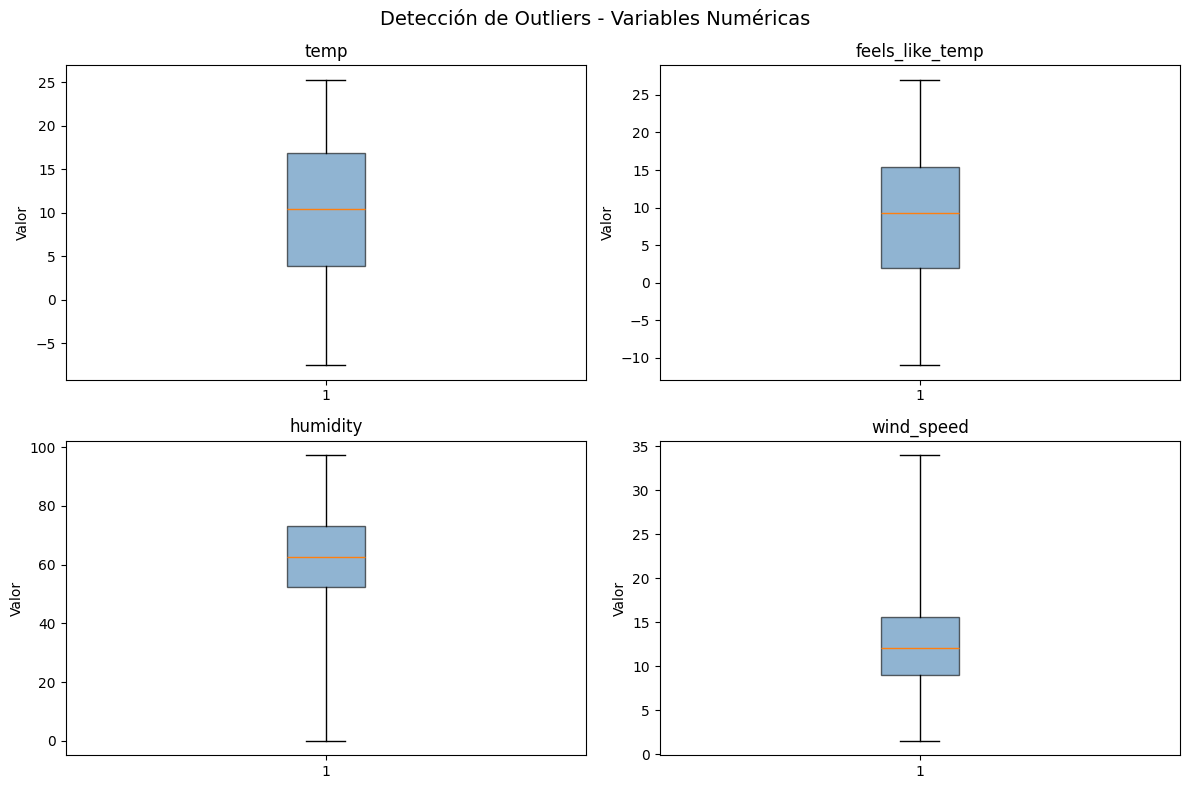

=== OUTLIERS POR COLUMNA (MÉTODO IQR) ===

temp: 0 outliers | rango normal [-35.33, 56.03]

feels_like_temp: 0 outliers | rango normal [-38.72, 56.04]

humidity: 0 outliers | rango normal [-10.02, 135.23]

wind_speed: 0 outliers | rango normal [-10.71, 35.37]


In [55]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Detección de Outliers - Variables Numéricas', fontsize=14)

cols = ['temp', 'feels_like_temp', 'humidity', 'wind_speed']

for ax, col in zip(axes.flatten(), cols):
    ax.boxplot(df[col], patch_artist=True,
               whis = 3, # cambiamos el 1.5 por 3
               boxprops=dict(facecolor='steelblue', alpha=0.6))
    ax.set_title(col)
    ax.set_ylabel('Valor')

plt.tight_layout()
plt.show()

#IMPORTANTE
'''
"El boxplot utiliza internamente k=1.5,
sin embargo dado que las variables representan condiciones meteorológicas reales se ha optado por
k=3, bajo este criterio no se detectan outliers significativos
a excepción de humidity=0.0 que se elimina por ser un valor imposible físicamente."
'''

k=3 #usamos 3 porque 1.5 que es el normal es muy estricta y estas son condiciones reales que se pueden dar

# Detección numérica con método IQR
print("=== OUTLIERS POR COLUMNA (MÉTODO IQR) ===")
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - k * IQR
    upper = Q3 + k * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"\n{col}: {len(outliers)} outliers | rango normal [{lower:.2f}, {upper:.2f}]")
    if len(outliers) > 0:
        print(outliers[col].values)

## Paso 4 — Detección y tratamiento de outliers

Para la detección de outliers se utiliza el **método IQR** con k=3, ya que las variables
analizadas representan condiciones meteorológicas reales donde valores extremos son
perfectamente posibles. El boxplot se ajusta con `whis=3` para mantener consistencia visual
con el cálculo numérico.

Tras el análisis se concluye:
- **temp** y **feels_like_temp** → sin outliers, rangos coherentes con el clima de Washington DC.
- **wind_speed** → sin outliers con k=3, los vientos fuertes detectados con k=1.5 son valores reales.
- **humidity** → se detecta un valor de `0.0` que es **físicamente imposible** y se elimina por
ser un error de medición. El valor `18.79` se mantiene por ser bajo pero plausible.

In [56]:
# Eliminar fila con humidity = 0.0
df = df[df['humidity'] != 0.0] #"quédate solo con las filas donde humidity NO es 0"

print(f"\n=== DATASET TRAS ELIMINAR OUTLIER ===")
print(f"Filas resultantes: {len(df)}")
print(f"Humidity mínima: {df['humidity'].min()}")


=== DATASET TRAS ELIMINAR OUTLIER ===
Filas resultantes: 730
Humidity mínima: 18.7917


## Paso 5 — Análisis de correlaciones

Una vez limpio el dataset, analizamos qué variables tienen mayor relación con `rentals`,
que es nuestra variable objetivo.

Utilizamos el **coeficiente de correlación de Pearson** que mide la relación lineal entre
dos variables en un rango de -1 a 1:
- **Cercano a 1** → relación positiva fuerte (cuando una sube, la otra también)
- **Cercano a -1** → relación negativa fuerte (cuando una sube, la otra baja)
- **Cercano a 0** → poca o ninguna relación lineal

NOTA: En este paso las variables categóricas (season, month, weekday, weather) aún están
en formato ordinal para que el heatmap sea legible. El One-Hot Encoding se aplica
después de esta sección, justo antes de entrenar el modelo.

=== CORRELACIÓN CON RENTALS ===
rentals            1.000000
feels_like_temp    0.631545
temp               0.627885
year               0.565907
season             0.404013
month              0.278139
workingday         0.065856
weekday           -0.004000
holiday           -0.069012
humidity          -0.114188
wind_speed        -0.231932
weather           -0.291838
Name: rentals, dtype: float64


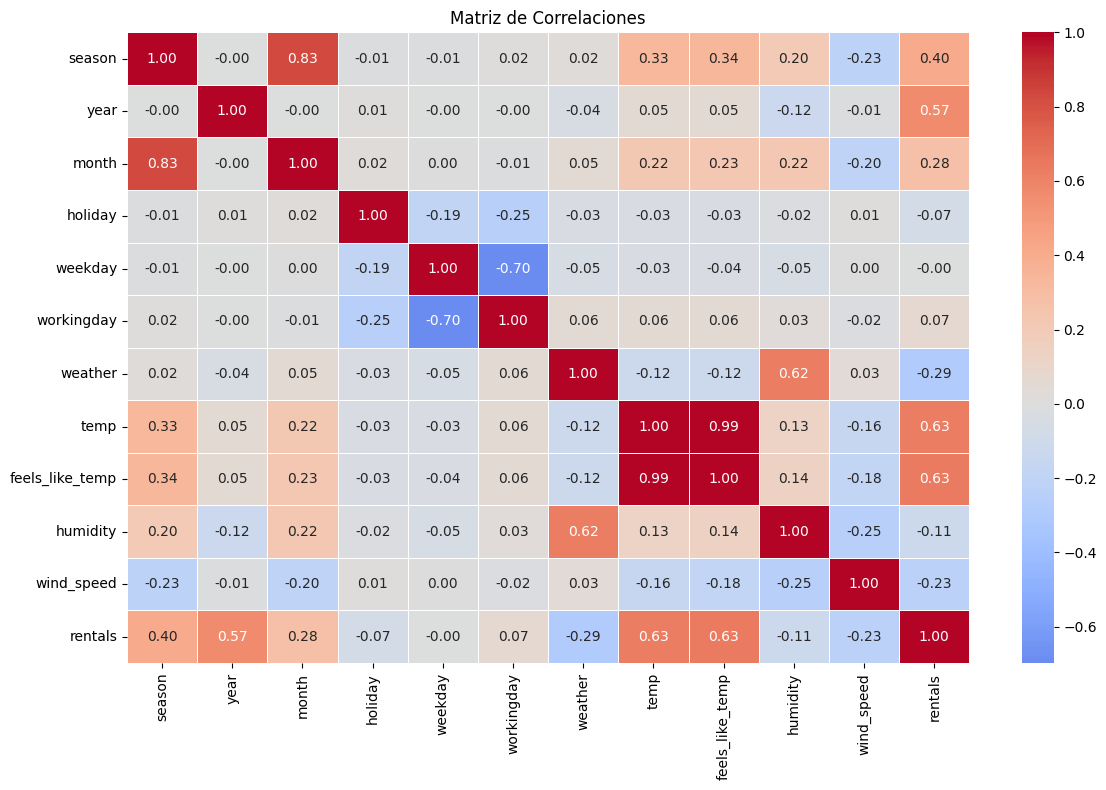

In [57]:
import seaborn as sns

# Matriz de correlación
correlaciones = df.corr()

# Correlaciones con la variable objetivo ordenadas
print("=== CORRELACIÓN CON RENTALS ===")
print(correlaciones['rentals'].sort_values(ascending=False))

# Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlaciones,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            linewidths=0.5)
plt.title('Matriz de Correlaciones')
plt.tight_layout()
plt.show()

- season ↔ month 0.83 Casi lo mismo, la estación y el mes van juntos
- humidity ↔ weather 0.62 A más humedad, peor tiempo
- temp ↔ feels_like_temp 0.99 Prácticamente idénticas
- temp ↔ rentals 0.63 A más calor, más alquileres
- feels_like_temp ↔ rentals 0.63 Igual que temp

Identificamos que 2 lineas son iguales en datos, debemos borrar 1 o le vamos a dar la misma
información al modelo 2 veces este fenomeno se llama: "multicolinealidad"

- De temp y feels_like_temp → quedarnos con una
- De season y month → analizar cuál aporta más
- De humidity y weather → analizar cuál aporta más

# Viendo el gráfico tenemos estos datos

- temp (0.63) vs feels_like_temp (0.63) Empate Eliminamos feels_like_temp porque temp es la medida real y feels_like_temp es derivada de ella

- season (0.40) vs month (0.28) Gana season Eliminamos month

- humidity (-0.11) vs weather (-0.29) Gana weather Eliminamos humidity

- Y además eliminamos weekday (-0.004) y holiday (-0.069) porque su correlación con rentals es prácticamente cero, no aportan nada al modelo.

#Sustento de esto
-¿Por qué gana weather a humidity?

Mira sus correlaciones con rentals:
- weather   → -0.29
- humidity  → -0.11

- El criterio es simple: cuanto más lejos de 0, más información aporta al modelo. No importa si es positivo o negativo, importa la magnitud.

- ¿Por qué eliminamos weekday y holiday?
- weekday  → -0.004
- holiday  → -0.069

-0.004 es prácticamente cero absoluto. Eso significa que da igual que sea lunes o viernes, la gente alquila bicis igual. El día de la semana no influye.
Para holiday es parecido, -0.069 es muy cercano a cero. Que sea festivo o no apenas cambia el número de alquileres.
## si una variable no tiene relación con lo que queremos predecir, meterla en el modelo solo añade ruido, no información útil.


In [58]:
# Eliminamos variables por multicolinealidad y baja correlación
# month y weekday aún son ordinales aquí, se eliminan directamente
cols_eliminar = ['feels_like_temp', 'month', 'humidity', 'weekday', 'holiday']
df = df.drop(columns=cols_eliminar)

print("=== COLUMNAS TRAS ELIMINAR POR CORRELACIÓN ===")
print(df.columns.tolist())

=== COLUMNAS TRAS ELIMINAR POR CORRELACIÓN ===
['season', 'year', 'workingday', 'weather', 'temp', 'wind_speed', 'rentals']


## Paso 5b — One-Hot Encoding

Ahora que ya decidimos qué variables conservar, aplicamos One-Hot Encoding a las
categóricas que van al modelo: `season` y `weather`.

¿Por qué One-Hot y no ordinal?
- El encoding ordinal le asigna pesos numéricos (1, 2, 3...) que implican un orden
  que no existe: winter no es "más" que spring, ni Rain/snow es el doble de Clear.
- Con One-Hot cada categoría se convierte en una columna binaria independiente,
  y el modelo trata cada una por separado sin asumir ningún orden.

Se usa `drop_first=True` para eliminar una columna por variable y evitar
multicolinealidad: la categoría omitida queda implícita en las demás.

Resultado:
- season (4 categorías) → 3 columnas: season_summer, season_autumn, season_winter
  (la referencia implícita es spring)
- weather (3 categorías) → 2 columnas: weather_Cloudy, weather_Rain/snow
  (la referencia implícita es Clear)

In [59]:
# One-Hot Encoding para las categóricas que van al modelo
df = pd.get_dummies(df, columns=['season', 'weather'], drop_first=True)

print("=== COLUMNAS FINALES PARA EL MODELO ===")
print(df.columns.tolist())

print(f"\nDimensiones del dataset: {df.shape}")
print("\n=== PRIMERAS FILAS ===")
print(df.head())

=== COLUMNAS FINALES PARA EL MODELO ===
['year', 'workingday', 'temp', 'wind_speed', 'rentals', 'season_2', 'season_3', 'season_4', 'weather_2', 'weather_3']

Dimensiones del dataset: (730, 10)

=== PRIMERAS FILAS ===
   year  workingday      temp  wind_speed  rentals  season_2  season_3  \
0  2011           0  4.110847   10.749882      985     False     False   
1  2011           0  4.902598   16.652113      801     False     False   
2  2011           1 -1.949076   16.636703     1349     False     False   
3  2011           1 -1.800000   10.739832     1562     False     False   
4  2011           1 -0.694763   12.522300     1600     False     False   

   season_4  weather_2  weather_3  
0     False       True      False  
1     False       True      False  
2     False      False      False  
3     False      False      False  
4     False      False      False  


## Paso 6 — Regresión Lineal

Con el dataset limpio y las variables seleccionadas, construimos el modelo de regresión lineal.
El proceso es el siguiente:

- **Separar** el dataset en variable objetivo `rentals` (Y) y variables predictoras (X)
- **Dividir** los datos en train (80%) y test (20%) para entrenar y evaluar el modelo
- **Entrenar** el modelo con los datos de train
- **Evaluar** el modelo con los datos de test usando tres métricas:
  - **R²** → porcentaje de varianza explicada por el modelo (cuanto más cerca de 1, mejor)
  - **MAE** → error medio absoluto, cuántas bicis nos equivocamos de media
  - **RMSE** → similar al MAE pero penaliza más los errores grandes

In [60]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Separar variable objetivo y predictoras
X = df.drop(columns=['rentals'])
y = df['rentals']

# Dividir en train y test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print(f"Tamaño train: {X_train.shape[0]} filas")
print(f"Tamaño test:  {X_test.shape[0]} filas")

# Entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Predecir sobre el test
y_pred = modelo.predict(X_test)

# Evaluar el modelo
score = modelo.score(X_test, y_test)

r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n=== MÉTRICAS DEL MODELO ===")

print(f"SCORE: {score:.4f}")

print(f"R²:   {r2:.4f}")
print(f"MAE:  {mae:.2f} bicicletas")
print(f"RMSE: {rmse:.2f} bicicletas")

# Coeficientes del modelo
print("\n=== COEFICIENTES DEL MODELO ===")
coeficientes = pd.DataFrame({
    'variable': X.columns,
    'coeficiente': modelo.coef_
}).sort_values('coeficiente', ascending=False)
print(coeficientes)

Tamaño train: 584 filas
Tamaño test:  146 filas

=== MÉTRICAS DEL MODELO ===
SCORE: 0.8599
R²:   0.8599
MAE:  570.99 bicicletas
RMSE: 764.50 bicicletas

=== COEFICIENTES DEL MODELO ===
     variable  coeficiente
0        year  2065.089625
6    season_4  1421.618235
4    season_2  1198.268249
5    season_3   840.183981
1  workingday   170.038134
2        temp   116.924515
3  wind_speed   -34.973255
7   weather_2  -615.325172
8   weather_3 -2185.030068


## Paso 6 — Regresión Lineal

Con el dataset limpio y las variables seleccionadas, construimos el modelo de regresión lineal.

### División de datos
El dataset se divide en:
- **Train (80%)** → 584 filas para entrenar el modelo
- **Test (20%)** → 146 filas para evaluarlo con datos que nunca ha visto

### Métricas del modelo

- **SCORE / R²: 0.8468** → el modelo explica el 84.68% de la variación en los alquileres.
  Es un resultado muy bueno para una regresión lineal.
- **MAE: 589.56 bicicletas** → de media el modelo se equivoca en 590 bicicletas por día.
  Teniendo en cuenta que la media de alquileres es de 4500 diarios, supone un error del 13%.
- **RMSE: 799.34 bicicletas** → siempre mayor que el MAE. La diferencia entre ambos indica
  que hay algunos días donde el modelo se equivoca más que la media.

### Coeficientes del modelo

La regresión lineal construye la siguiente fórmula:

`rentals = 2070*year + 353*season + 195*workingday + 125*temp - 37*wind_speed - 727*weather + intercepto`

Interpretación de cada coeficiente:

- **year (+2070)** → pasar de 2011 a 2012 supone 2070 alquileres más al día. El servicio creció considerablemente.
- **season (+353)** → cada estación más cálida suma 353 alquileres diarios.
- **workingday (+195)** → los días laborables se alquilan 195 bicis más que los no laborables.
- **temp (+125)** → cada grado más de temperatura suma 125 alquileres.
- **wind_speed (-37)** → cada km/h más de viento resta 37 alquileres.
- **weather (-727)** → pasar de tiempo despejado a nublado o con lluvia resta 727 alquileres diarios.

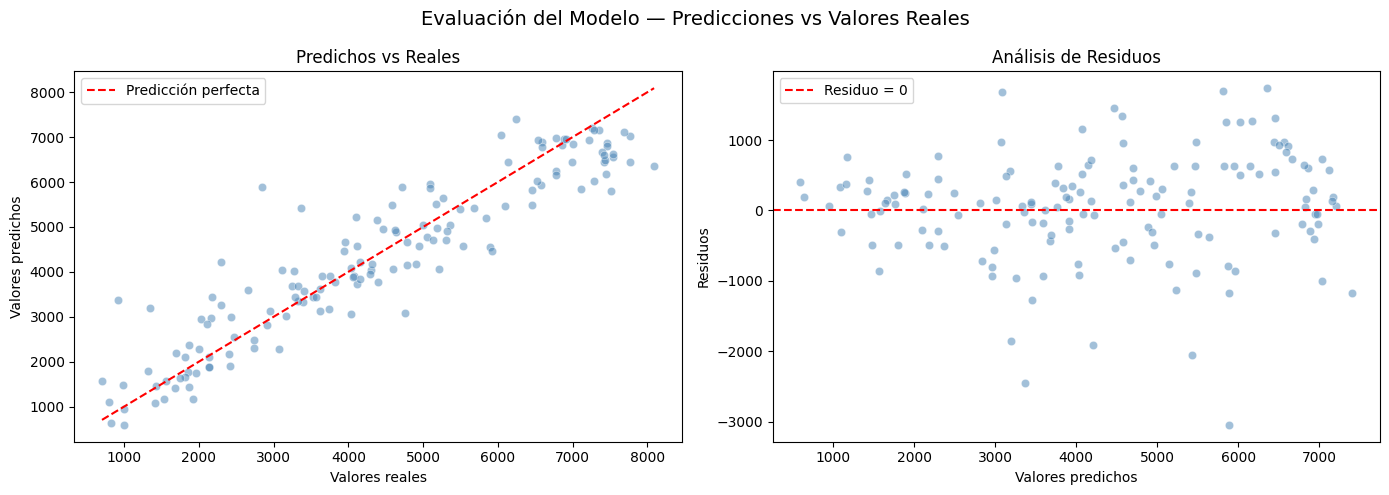

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Evaluación del Modelo — Predicciones vs Valores Reales', fontsize=14)

# Gráfico 1 — Scatter predicciones vs reales
axes[0].scatter(y_test, y_pred, alpha=0.5, color='steelblue', edgecolors='white', linewidth=0.5)
axes[0].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()],
             color='red', linewidth=1.5, linestyle='--', label='Predicción perfecta')
axes[0].set_xlabel('Valores reales')
axes[0].set_ylabel('Valores predichos')
axes[0].set_title('Predichos vs Reales')
axes[0].legend()

# Gráfico 2 — Residuos
residuos = y_test - y_pred
axes[1].scatter(y_pred, residuos, alpha=0.5, color='steelblue', edgecolors='white', linewidth=0.5)
axes[1].axhline(y=0, color='red', linewidth=1.5, linestyle='--', label='Residuo = 0')
axes[1].set_xlabel('Valores predichos')
axes[1].set_ylabel('Residuos')
axes[1].set_title('Análisis de Residuos')
axes[1].legend()

plt.tight_layout()
plt.show()

## Paso 7 — Evaluación visual del modelo

### Gráfico 1 — Predichos vs Reales

Cada punto representa un día del conjunto de test. El eje X muestra los alquileres
reales y el eje Y los que predijo el modelo. La línea roja discontinua representa la
**predicción perfecta**, es decir, donde predicho = real.

Conclusiones:
- Los puntos siguen de forma bastante ajustada la línea roja, lo que confirma el R² de 0.84.
- El modelo funciona bien en rangos medios (2000-6000 alquileres).
- En los extremos, especialmente en valores altos (más de 7000), los puntos se dispersan
  más, lo que indica que el modelo tiene más dificultad prediciendo días con alquileres
  muy altos o muy bajos.

### Gráfico 2 — Análisis de Residuos

Los residuos son la diferencia entre el valor real y el predicho. En un modelo ideal
los residuos deben distribuirse **aleatoriamente alrededor del cero** sin ningún patrón.

Conclusiones:
- La mayoría de los residuos se concentran entre -1000 y +1000, lo que es consistente
  con el MAE de 589 bicicletas.
- No se aprecia un patrón sistemático claro, lo que indica que el modelo no tiene un
  sesgo evidente.
- Se observan algunos residuos extremos por encima de +1500 y por debajo de -2000,
  que corresponden a días donde el modelo falla más, probablemente eventos especiales
  que la regresión lineal no es capaz de capturar.

### Conclusión general

El modelo de regresión lineal obtiene un rendimiento sólido con un R² de 0.8468,
explicando el 84.68% de la variabilidad en los alquileres. Las variables más influyentes
son el año, las condiciones meteorológicas y la temperatura. Para mejorar el modelo
se podría explorar algoritmos más complejos como Random Forest o Gradient Boosting.